In [ ]:
Abror Joraboyev
ID 230363

In [1]:
pip install opencv-python 'numpy<2' matplotlib

Defaulting to user installation because normal site-packages is not writeable
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 18.5 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.13.0.90
    Uninstalling opencv-python-4.13.0.90:
      Successfully uninstalled opencv-python-4.13.0.90
Note: you may need to restart the kernel to use updated packages.


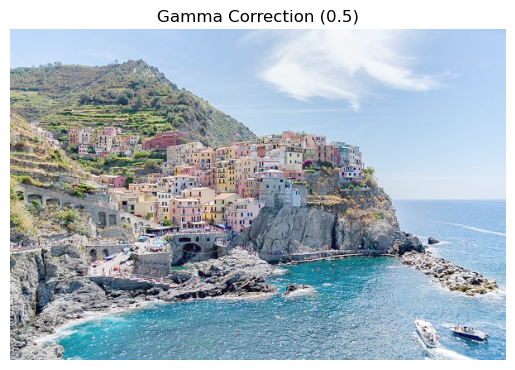

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def gamma_correction(image, gamma):
    if image is None:
        raise ValueError('Image not loaded')
    if gamma <= 0:
        raise ValueError('Gamma must be > 0')
    img = image.astype(np.float32) / 255.0
    corrected = np.power(img, gamma)
    corrected = np.clip(corrected * 255.0, 0, 255).astype(np.uint8)
    return corrected


img = cv2.imread('/Users/230363/Downloads/img.jpg')
if img is None:
    print('/Users/230363/Downloads/img.jpg')
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gamma_img = gamma_correction(img_rgb, 0.5)
    plt.figure()
    plt.title('Gamma Correction (0.5)')
    plt.imshow(gamma_img)
    plt.axis('off')
    plt.show()


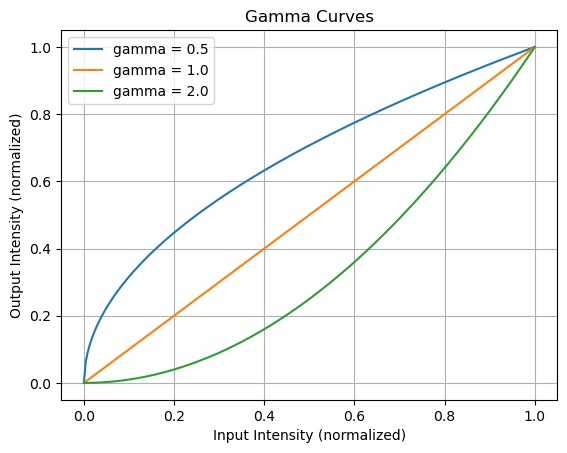

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 1, 256)
plt.figure()
for g in [0.5, 1.0, 2.0]:
    y = np.power(x, g)
    plt.plot(x, y, label=f'gamma = {g}')

plt.title('Gamma Curves')
plt.xlabel('Input Intensity (normalized)')
plt.ylabel('Output Intensity (normalized)')
plt.legend()
plt.grid(True)
plt.show()


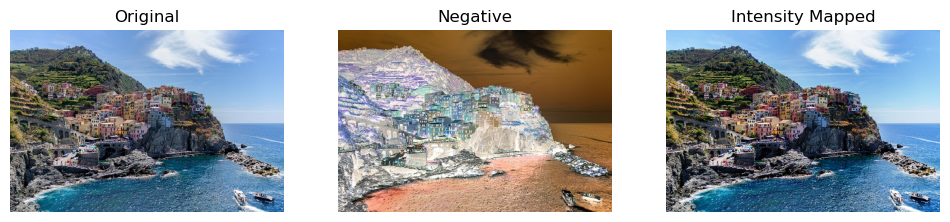

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def image_negative(image):
    return 255 - image

def intensity_range_mapping(image, r1, r2, s1, s2):
    img = image.astype(np.float32)
    out = np.zeros_like(img)

    mask1 = img < r1
    mask2 = (img >= r1) & (img <= r2)
    mask3 = img > r2

    if r1 != 0:
        out[mask1] = (s1 / r1) * img[mask1]
    out[mask2] = ((s2 - s1) / (r2 - r1)) * (img[mask2] - r1) + s1
    out[mask3] = ((255 - s2) / (255 - r2)) * (img[mask3] - r2) + s2

    return np.clip(out, 0, 255).astype(np.uint8)


img = cv2.imread('/Users/230363/Downloads/img.jpg')
if img is None:
    print('/Users/230363/Downloads/img.jpg')
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    neg = image_negative(img_rgb)
    mapped = intensity_range_mapping(img_rgb, 50, 200, 30, 220)

    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1); plt.title('Original'); plt.imshow(img_rgb); plt.axis('off')
    plt.subplot(1,3,2); plt.title('Negative'); plt.imshow(neg); plt.axis('off')
    plt.subplot(1,3,3); plt.title('Intensity Mapped'); plt.imshow(mapped); plt.axis('off')
    plt.show()


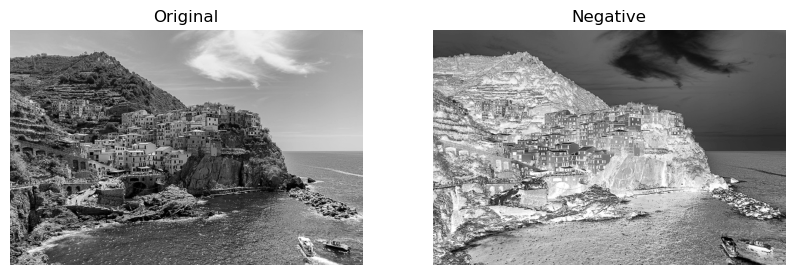

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img = cv2.imread('/Users/230363/Downloads/img.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError('/Users/230363/Downloads/img.jpg')

negative = np.zeros_like(img, dtype=np.uint8)

h, w = img.shape
for i in range(h):
    for j in range(w):
        negative[i, j] = 255 - img[i, j]   


plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.title("Original")
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.title("Negative")
plt.imshow(negative, cmap="gray")
plt.axis("off")

plt.show()

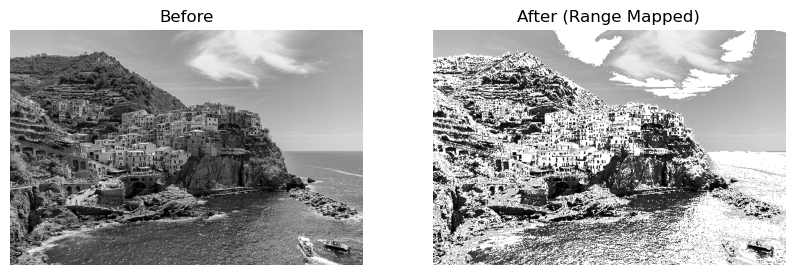

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img = cv2.imread("img.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError("img.jpg")

A = 80   
B = 160  

mapped = img.copy()

h, w = img.shape
for i in range(h):
    for j in range(w):
        if A <= img[i, j] <= B:
            mapped[i, j] = 255  
        else:
            mapped[i, j] = img[i, j]  


plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.title("Before")
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.title("After (Range Mapped)")
plt.imshow(mapped, cmap="gray")
plt.axis("off")

plt.show()

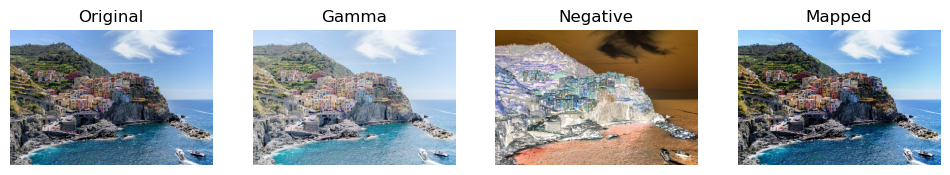

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def full_pipeline(image):
    gamma_img = gamma_correction(image, 0.5)
    neg_img = image_negative(image)
    mapped_img = intensity_range_mapping(image, 50, 200, 30, 220)
    return gamma_img, neg_img, mapped_img

img = cv2.imread('/Users/230363/Downloads/img.jpg')
if img is None:
    print('/Users/230363/Downloads/img.jpg')
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    g, n, m = full_pipeline(img_rgb)

    plt.figure(figsize=(12,4))
    plt.subplot(1,4,1); plt.title('Original'); plt.imshow(img_rgb); plt.axis('off')
    plt.subplot(1,4,2); plt.title('Gamma'); plt.imshow(g); plt.axis('off')
    plt.subplot(1,4,3); plt.title('Negative'); plt.imshow(n); plt.axis('off')
    plt.subplot(1,4,4); plt.title('Mapped'); plt.imshow(m); plt.axis('off')
    plt.show()


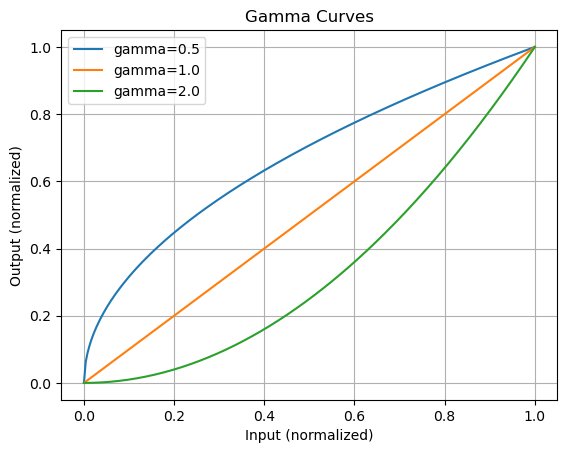

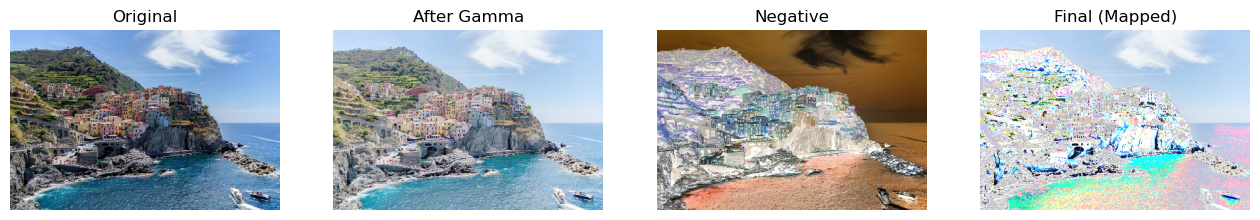

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def _validate_image(image):
    if image is None:
        raise ValueError("Image is None. Check the path.")
    if not isinstance(image, np.ndarray):
        raise TypeError("Image must be a numpy array.")
    if image.dtype != np.uint8:
        raise TypeError("Image must be uint8.")
    if image.ndim not in (2, 3):
        raise ValueError("Image must be grayscale (2D) or RGB (3D).")

def _to_float01(image):
    return image.astype(np.float32) / 255.0

def _to_uint8(image01):
    return np.clip(image01 * 255.0, 0, 255).astype(np.uint8)

def gamma_correction(image, gamma):
    _validate_image(image)
    if gamma <= 0:
        raise ValueError("Gamma must be > 0")

    img01 = _to_float01(image)
    corrected01 = np.power(img01, gamma)
    return _to_uint8(corrected01)

def image_negative(image):
    _validate_image(image)
    return 255 - image

def intensity_range_mapping(image, A, B):
    _validate_image(image)
    if not (0 <= A <= 255 and 0 <= B <= 255):
        raise ValueError("A and B must be in [0, 255]")
    if A > B:
        raise ValueError("A must be <= B")

    out = image.copy()
    mask = (image >= A) & (image <= B)
    out[mask] = 255
    return out

def show_images(title_list, image_list):
    n = len(image_list)
    plt.figure(figsize=(4*n, 4))
    for i, (title, img) in enumerate(zip(title_list, image_list)):
        plt.subplot(1, n, i+1)
        plt.title(title)
        if img.ndim == 2:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(img)
        plt.axis("off")
    plt.show()

def plot_gamma_curves(gammas=(0.5, 1.0, 2.0)):
    x = np.linspace(0, 1, 256)
    plt.figure()
    for g in gammas:
        y = np.power(x, g)
        plt.plot(x, y, label=f"gamma={g}")
    plt.title("Gamma Curves")
    plt.xlabel("Input (normalized)")
    plt.ylabel("Output (normalized)")
    plt.legend()
    plt.grid(True)
    plt.show()


img_bgr = cv2.imread('/Users/230363/Downloads/img.jpg')
if img_bgr is None:
    raise ValueError('/Users/230363/Downloads/img.jpg')

img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plot_gamma_curves(gammas=(0.5, 1.0, 2.0))

gamma_img = gamma_correction(img, gamma=0.5)

neg_img = image_negative(img)

A, B = 80, 160
mapped_img = intensity_range_mapping(gamma_img, A, B)

show_images(
    ["Original", "After Gamma", "Negative", "Final (Mapped)"],
    [img, gamma_img, neg_img, mapped_img]
)
